# Using SIMPLEOmics to integrate RNA data from E15 mouse brain and ATAC data from E18 mouse brain (diagnal integration)

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import SIMPLEOmics

import os
import torch
import numpy as np

# the location of R (used for the mclust clustering)
os.environ['R_HOME'] = "/home/lvyz/miniconda3/envs/SIMPLEOmics_env/lib/R"
os.environ['R_USER'] = "/home/lvyz/miniconda3/envs/SIMPLEOmics_env/lib/python3.8/site-packages/rpy2"
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.sparse import block_diag
import pandas as pd
from scipy.sparse import csr_matrix
used_device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
print(torch.cuda.is_available())

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "svg.fonttype": "none"
})

# set seed
seed=2026
SIMPLEOmics.ST_utils.fix_seed(seed)

True


## 2. Load data and preprocessing for training

In [ ]:
# load data
n_cluster=14
file_folds = ['/data_SIMPLEOmics/Mouse_brain_E15_S1/','/data_SIMPLEOmics/Mouse_brain_E18_S1/']  #please replace 'file_fold' with the download path
name = ["Mouse_Brain_E15_S1","Mouse_Brain_E18_S1"]

edge_index_atac_list = []
edge_index_rna_list = []
offset_rna = 0
offset_atac = 0
rna_adatas = {}
atac_adatas = {}
for file_fold, name in zip(file_folds, name):
    if name == 'Mouse_Brain_E18_S1':
        adata_omics2 = sc.read_h5ad(file_fold + 'adata_ATAC.h5ad')
        adata_omics2.obs["anno"]=pd.read_csv(file_fold+"anno.csv",index_col=0)["cluster"]
        adata_omics2.var_names_make_unique()
        adata_omics2=SIMPLEOmics.Cal_Net(adata_omics2)
        atac_adatas[name] = adata_omics2.copy()
        edge_index_atac = adata_omics2.uns['edge_index']
        edge_index_atac = edge_index_atac + offset_atac
        offset_atac += adata_omics2.n_obs
        edge_index_atac_list.append(edge_index_atac)
    else:
        adata_omics1 = sc.read_h5ad(file_fold + 'adata_RNA.h5ad')
        adata_omics1.obs["anno"]=pd.read_csv(file_fold+"anno.csv",index_col=0)["cluster"]
        adata_omics1.var_names_make_unique()
        adata_omics1=SIMPLEOmics.Cal_Net(adata_omics1)
        rna_adatas[name] = adata_omics1.copy()
        edge_index_rna = adata_omics1.uns['edge_index']
        edge_index_rna = edge_index_rna + offset_rna
        offset_rna += adata_omics1.n_obs
        edge_index_rna_list.append(edge_index_rna)

adata_rna=sc.concat(rna_adatas, label="batch",index_unique="_")
adata_atac=sc.concat(atac_adatas, label="batch",index_unique="_")
edge_index_rna_concat = np.hstack(edge_index_rna_list)
adata_rna.uns['edge_index'] = edge_index_rna_concat

adata_rna.uns['adj']  = block_diag([i.uns["adj"] for i in rna_adatas.values()])
edge_index_atac_concat = np.hstack(edge_index_atac_list)
adata_atac.uns['edge_index'] = edge_index_atac_concat
adata_atac.uns['adj']  = block_diag([i.uns["adj"] for i in atac_adatas.values()])

# RNA
if isinstance(adata_rna.X, np.ndarray):
    adata_rna.X = csr_matrix(adata_rna.X)
sc.pp.filter_genes(adata_rna, min_cells=10)
sc.pp.highly_variable_genes(adata_rna, flavor="seurat_v3", n_top_genes=5000)
sc.pp.normalize_total(adata_rna, target_sum=1e4)
sc.pp.log1p(adata_rna)
sc.pp.scale(adata_rna)
adata_rna =  adata_rna[:, adata_rna.var['highly_variable']]
adata_rna.obsm["feat"] = SIMPLEOmics.ST_utils.pca(adata_rna,n_comps=60,random_state=seed)

# ATAC
from muon import atac as ac
ac.pp.tfidf(adata_atac, scale_factor=1e4)
sc.pp.normalize_per_cell(adata_atac, counts_per_cell_after=1e4)
sc.pp.log1p(adata_atac)
adata_atac.obsm['feat'] = SIMPLEOmics.ST_utils.pca(adata_atac,n_comps=60,random_state=seed)

------Calculating Spatial Graph (k=6, metric=euclidean)...
Spatial edges: 11694
------Calculating Spatial Graph (k=6, metric=euclidean)...
Spatial edges: 12774


## 3. Training SIMPLEOmics

In [3]:
# training SIMPLEOmics
adata_rna,adata_atac,adata_joint = SIMPLEOmics.train_unpaired(adata_rna,adata_atac,num_prototype=n_cluster,gamma_homo=0.05,device=used_device,random_seed=seed)

60
60
training SIMPLEOmics...


100%|██████████| 1000/1000 [12:45<00:00,  1.31it/s]


Building joint AnnData
RNA spots: 1949
ATAC spots: 2129
Common spots: 0
RNA-only spots: 1949
ATAC-only spots: 2129
Final unique spots: 4078
Final adata_joint shape: (4078, 1)


## 4. Clustering

In [4]:
# clustering
adata_rna2 = adata_rna.copy()
SIMPLEOmics.ST_utils.mclust_R(adata_rna2, num_cluster=n_cluster, used_obsm='omic1_embedding',random_seed=seed)
SIMPLEOmics.ST_utils.mclust_R(adata_atac, num_cluster=n_cluster, used_obsm='omic2_embedding',random_seed=seed)

# ari
adata_rna2.obs["mclust"] = adata_rna2.obs["mclust"].astype(int).astype("category")
adata_atac.obs["mclust"] = adata_atac.obs["mclust"].astype(int).astype("category")
from sklearn.metrics import adjusted_rand_score
batch_list=[]
ari_list=[]
name = ["Mouse_Brain_E15_S1","Mouse_Brain_E18_S1"]
adata_rna1=adata_rna[~adata_rna.obs['anno'].isna()]
for i in range(2):
    adata_i = adata_rna2[adata_rna2.obs['batch'] == name[i]]
    ari_i = adjusted_rand_score(adata_i.obs['anno'], adata_i.obs["mclust"])
    ari_list.append(ari_i)
adata_atac1=adata_atac[~adata_atac.obs['anno'].isna()]
for i in range(2):
    adata_i = adata_atac1[adata_atac1.obs['batch'] == name[i]]
    ari_i = adjusted_rand_score(adata_i.obs['anno'], adata_i.obs["mclust"])
    ari_list.append(ari_i)

R[write to console]:     __  ___________    __  _____________
   /  |/  / ____/ /   / / / / ___/_  __/
  / /|_/ / /   / /   / / / /\__ \ / /   
 / /  / / /___/ /___/ /_/ /___/ // /    
/_/  /_/\____/_____/\____//____//_/    version 5.4.7
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%
fitting ...
  |======================================================================| 100%


## 5. Visualization

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


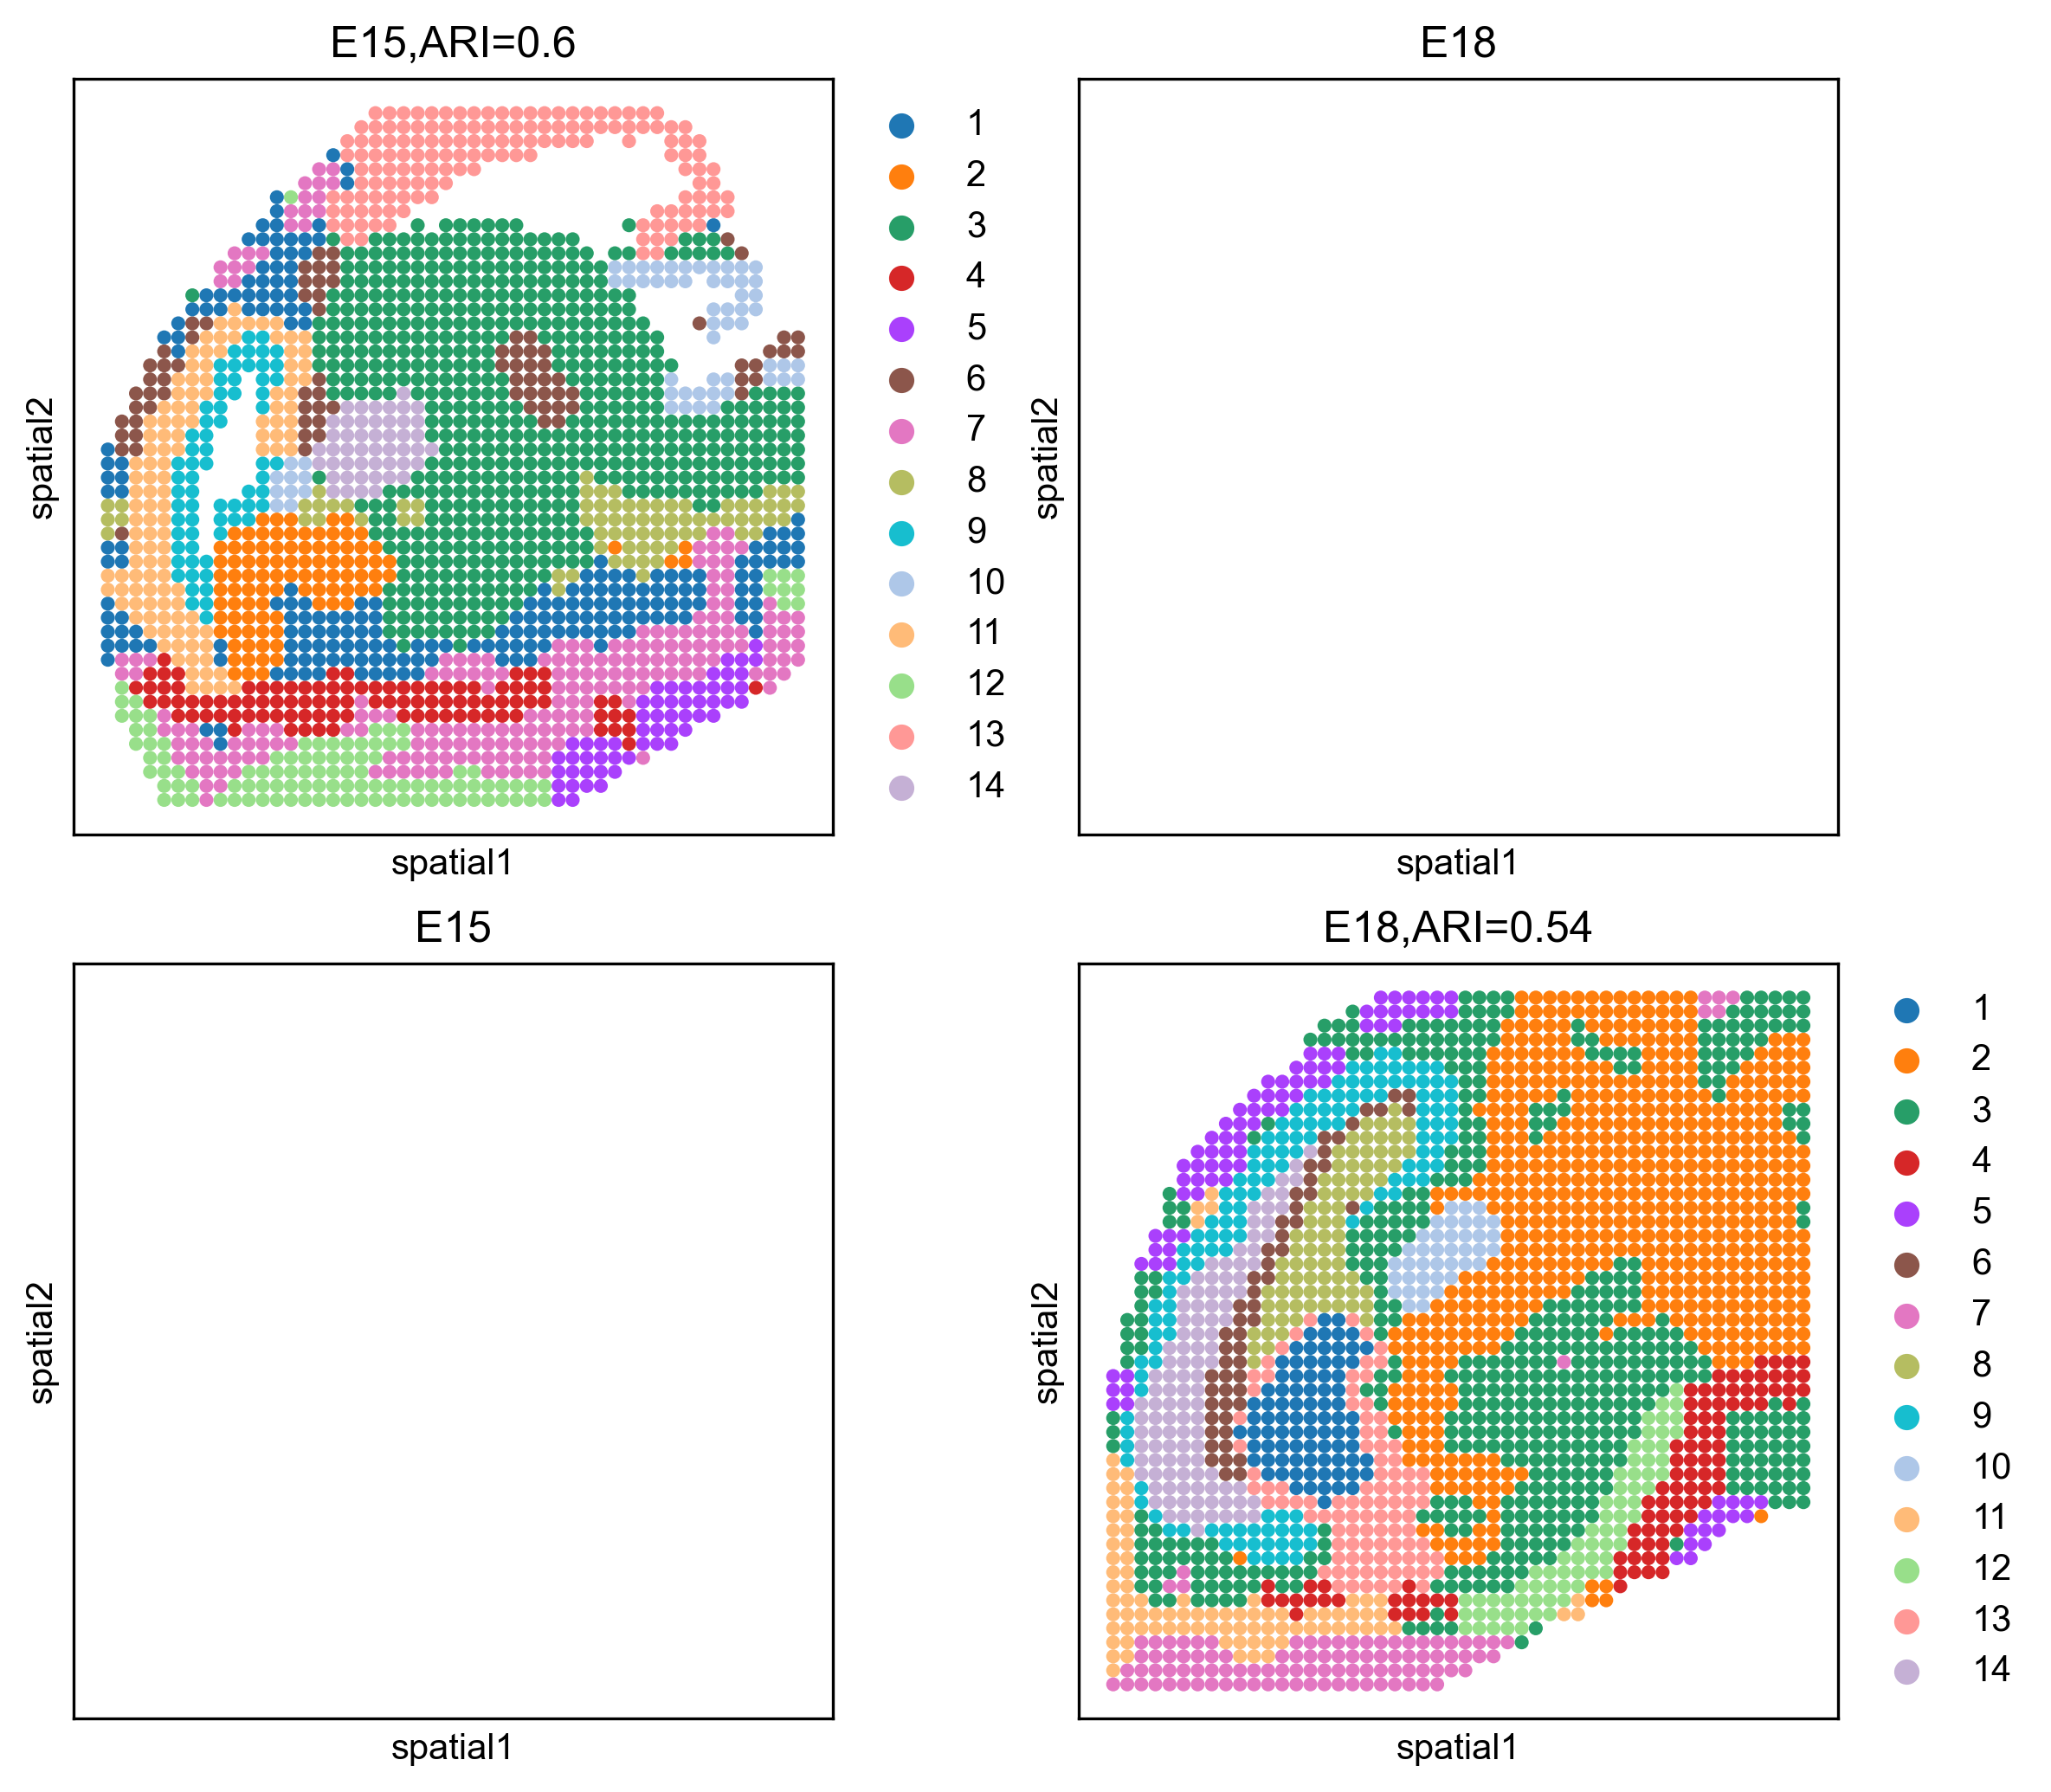

In [5]:
# visualization
import matplotlib.pyplot as plt
fig, ax_list = plt.subplots(2, 2, figsize=(8, 7),dpi=300)
ax_list = ax_list.flatten()
sc.pl.embedding(adata_rna2[adata_rna2.obs["batch"]==name[0]].copy(), basis='spatial', color='mclust', ax=ax_list[0], title='E15,ARI='+str(round(ari_list[0],2)), s=60, show=False)
sc.pl.embedding(adata_rna2[adata_rna2.obs["batch"]==name[1]].copy(), basis='spatial', color='mclust', ax=ax_list[1], title='E18', s=60, show=False)
sc.pl.embedding(adata_atac[adata_atac.obs["batch"]==name[0]].copy(), basis='spatial', color='mclust', ax=ax_list[2], title='E15', s=60, show=False)
sc.pl.embedding(adata_atac[adata_atac.obs["batch"]==name[1]].copy(), basis='spatial', color='mclust', ax=ax_list[3], title='E18,ARI='+str(round(ari_list[3],2)), s=60, show=False)
ax_list[2].get_legend().remove()

plt.tight_layout(w_pad=0.3, h_pad=0.8)
plt.show()